# CloudGuard-Water: Complete Project Notebook
## Intelligent and Explainable Water Quality Classification Using Machine Learning

**Course**: Machine Learning for Cloud Services (MLCS)  
**Academic Institution / Project**: CloudGuard-Water Comprehensive Technical Monograph  
**Author**: Lead Systems, ML Deployment & IoT Verification Specialist  
**Canonical Dataset**: `data/water_quality_dataset1.csv` (100,800 observations, 4 physical features, 1 target label)  
**Authoritative Model**: `models/decision_tree.joblib` (`DecisionTreeClassifier(max_depth=5)`, 27 nodes, 14 leaves)  
**Benchmarking Model**: `models/random_forest.joblib` (`RandomForestClassifier(n_estimators=100, max_depth=8)`)  
**Reference Model**: `models/logistic_regression.joblib` (Pipeline: `StandardScaler` + `LogisticRegression`)  
**Microservice Endpoint**: `api/main.py` (FastAPI REST microservice)  
**Interactive Dashboard**: `dashboard/` (Mounted at `http://127.0.0.1:8000/dashboard`)  
**Date**: October 2026  

---

## 1. Project Overview & System Architecture

### 1.1 Problem Statement & Background
Water quality monitoring in municipal, industrial, and agricultural contexts has historically relied upon manual grab-sampling, localized chemical titrations, and delayed off-site microbiological assays. This manual workflow introduces multi-day latency between contamination events and public health interventions.

Modern Internet of Things (IoT) hardware and cloud machine learning architectures enable real-time continuous ingestion of physical aqueous properties. However, real-time edge monitoring introduces two fundamental engineering challenges:
1. **Explainability & Trust**: Black-box machine learning models cannot be audited during critical failure modes. Domain operators need to know *why* an anomaly was flagged before triggering field inspections.
2. **Operational Safety & Domain Boundaries**: Basic physical sensors (pH, TDS, turbidity, temperature) cannot detect microbiological pathogens (*E. coli*, noroviruses) or toxic heavy metals (lead, arsenic). Therefore, a statistical ML classification must never be misrepresented as an official drinking-water potability certification, and automated physical actuation (valves/pumps) must remain strictly disabled.

### 1.2 Project Scope & Objectives
The CloudGuard-Water project delivers a complete, production-grade end-to-end software and IoT architecture:
- **Phase 1 & 2**: Canonical dataset inspection, statistical profiling, and exploratory data analysis.
- **Phase 3 & 4**: Baseline model training, cross-validation, and selection of an optimal explainable model (Decision Tree).
- **Phase 4.1**: Comprehensive dataset provenance and consistency audit, debunking manufactured temporal features.
- **Phase 5**: White-box decision tree path extraction, learned threshold comparisons, and plain-English narrative explainability.
- **Phase 6 & 6.1**: Production FastAPI cloud microservice with Pydantic v2 validation, 1D training-range warnings, and probability estimation.
- **Phase 7, 7.1, 7.2, 7.3**: ESP32 physical IoT circuit design, ADC non-linearity compensation, Option D ($15\,\text{k}\Omega : 10\,\text{k}\Omega$) voltage divider headroom finalization, and firmware compilation.
- **Phase 8**: Responsive, zero-dependency web dashboard integrating real-time sensor cards, tree traversal ladders, canvas charts, and preset demo scenarios.

### 1.3 End-to-End System Architecture

```
┌─────────────────────────────────────────────────────────────────────────────────┐
│                           1. PHYSICAL IoT SENSING LAYER                         │
│                                                                                 │
│   Analog pH Probe      Analog TDS Sensor     Optical Turbidity     DS18B20 Temp │
│   [0 - 5.0V output]    [0 - 2.3V output]     [0 - 4.5V output]     [Digital 1W] │
│          │                     │                     │                   │      │
│          ▼                     ▼                     ▼                   │      │
│   ┌──────────────┐             │              ┌──────────────┐           │      │
│   │Option D Div. │             │              │Option D Div. │           │      │
│   │15k : 10k     │      Direct 3.3V           │15k : 10k     │           │      │
│   │(5V -> 2.0V)  │       Connection           │(4.5V->1.8V)  │           │      │
│   └──────┬───────┘             │              └──────┬───────┘           │      │
│          │                     │                     │                   │      │
│          ▼                     ▼                     ▼                   ▼      │
│   GPIO 34 (ADC1_CH6)    GPIO 35 (ADC1_CH7)    GPIO 32 (ADC1_CH4)       GPIO 4   │
│   ┌─────────────────────────────────────────────────────────────────────────┐   │
│   │                    ESP32-WROOM-32 MICROCONTROLLER                       │   │
│   │  • factory eFuse analogReadMilliVolts() calibration                     │   │
│   │  • Over-sampling (N=10) + Noise Filtering                               │   │
│   │  • Voltage Multiplier (M = 2.50x) + Physical Conversion Equations       │   │
│   │  • Wi-Fi HTTP Client Telemetry Dispatch (JSON Payload)                  │   │
│   └───────────────────────────────────┬─────────────────────────────────────┘   │
└───────────────────────────────────────┼─────────────────────────────────────────┘
                                        │ Local Wi-Fi / HTTP POST
                                        ▼
┌─────────────────────────────────────────────────────────────────────────────────┐
│                       2. CLOUD REST MICROSERVICE (FastAPI)                      │
│                                                                                 │
│   GET  /health      ──> Readiness probe & in-memory model status                │
│   POST /predict     ──> Statistical classification & class probabilities        │
│   POST /explain     ──> Sequential tree path traversal & auditable narrative    │
│   GET  /dashboard/  ──> Static web dashboard presentation layer                 │
│                                                                                 │
│   ┌─────────────────────────────────────────────────────────────────────────┐   │
│   │                     Pydantic v2 Schema Validation                       │   │
│   │  • Strict domain boundaries: 0<=pH<=14, TDS>=0, Turb>=0, -10<=Temp<=100 │   │
│   │  • Marginal training-range checks: pH [6.09, 9.96], TDS [28.6, 2806.1]  │   │
│   └───────────────────────────────────┬─────────────────────────────────────┘   │
│                                       │ Canonical Ordered Features              │
│                                       ▼                                         │
│   ┌─────────────────────────────────────────────────────────────────────────┐   │
│   │                Explainable Machine Learning Engine                      │   │
│   │  • models/decision_tree.joblib (Depth=5, 27 nodes, 14 leaves)           │   │
│   │  • Exact decision path extraction via scikit-learn decision_path()      │   │
│   └───────────────────────────────────┬─────────────────────────────────────┘   │
└───────────────────────────────────────┼─────────────────────────────────────────┘
                                        │ REST API Response (JSON)
                                        ▼
┌─────────────────────────────────────────────────────────────────────────────────┐
│                    3. PRESENTATION LAYER (Web Dashboard)                        │
│                                                                                 │
│   • 4 Real-Time Sensor Cards (pH, TDS, Turbidity, Temp) with animated gauges   │
│   • Decision Tree Traversal Ladder (exact nodes, rules, values, and branches)   │
│   • Estimated Class Probabilities with horizontal ratio fill bars               │
│   • HTML5 Canvas 2D Rolling Time-Series Telemetry Plotter (30 samples)          │
│   • Telemetry Mode Banners: DEMO DATA ALERT vs LIVE HARDWARE STANDBY            │
│   • Statutory Safety Notice (Pathogen non-certification & disabled actuation)   │
└─────────────────────────────────────────────────────────────────────────────────┘
```

### 1.4 Table of Contents
1. [Project Overview & System Architecture](#1-project-overview--system-architecture)
2. [Canonical Dataset Inspection & Data Dictionary](#2-canonical-dataset-inspection--data-dictionary)
3. [Exploratory Data Analysis (EDA)](#3-exploratory-data-analysis-eda)
4. [Data Preprocessing & Baseline Model Architecture](#4-data-preprocessing--baseline-model-architecture)
5. [Comprehensive Model Evaluation & Model Selection](#5-comprehensive-model-evaluation--model-selection)
6. [Dataset Provenance & Consistency Audit](#6-dataset-provenance--consistency-audit)
7. [Model Explainability & Transparent Decision Logic](#7-model-explainability--transparent-decision-logic)
8. [FastAPI Cloud REST Microservice](#8-fastapi-cloud-rest-microservice)
9. [API Calibration & Defensive Validation Audit](#9-api-calibration--defensive-validation-audit)
10. [IoT Circuit Architecture & Sensor Pinouts](#10-iot-circuit-architecture--sensor-pinouts)
11. [Electrical Schematic & Power Isolation Audit](#11-electrical-schematic--power-isolation-audit)
12. [ADC Non-Linearity & Voltage Calibration](#12-adc-non-linearity--voltage-calibration)
13. [Final Circuit Headroom & Commissioning Readiness](#13-final-circuit-headroom--commissioning-readiness)
14. [Interactive Web Dashboard & Software Integration](#14-interactive-web-dashboard--software-integration)
15. [Full System Architecture & Comprehensive Verification Matrix](#15-full-system-architecture--comprehensive-verification-matrix)
16. [Operational Limitations, Future Work & Conclusion](#16-operational-limitations-future-work--conclusion)


---
## 2. Canonical Dataset Inspection & Data Dictionary

### 2.1 Authoritative Dataset Properties
The authoritative dataset for all model training and evaluation is `data/water_quality_dataset1.csv`:
- **Dimensions**: Exactly 100,800 rows and 5 columns.
- **Input Features** (4): `pH`, `TDS_ppm`, `Turbidity_NTU`, `Temperature_C`.
- **Target Label** (1): `Label` with binary classes `Safe` (30,240 rows, 30.0%) and `Unsafe` (70,560 rows, 70.0%).
- **Missing Values**: 0 nulls across all cells.
- **Duplicate Rows**: 0 duplicate rows.
- **File Integrity**: Verified via cryptographic SHA-256 hash comparison.

### 2.2 Corrected Data Dictionary & Standards Comparison Table
The table below distinguishes the **observed dataset ranges** from official drinking-water specifications established by the **Bureau of Indian Standards (BIS IS 10500:2012)** and **World Health Organization (WHO) Guidelines for Drinking-water Quality (4th Edition)**:

| Column Name | Physical Quantity | Scale / Units | Observed Dataset Range | BIS IS 10500:2012 Acceptable Limit | BIS IS 10500:2012 Permissible Limit | WHO Guidelines (4th Edition) Guidance |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **`pH`** | Potential of Hydrogen | Aqueous scale [$0.0, 14.0$] | $6.09 - 9.96$ | $6.5 - 8.5$ | No relaxation | Operational guideline: $6.5 - 8.5$ for effective chlorination disinfection |
| **`TDS_ppm`** | Total Dissolved Solids | $\text{mg/L}$ ($\text{ppm}$) | $28.6 - 2806.1\,\text{ppm}$ | $500\,\text{mg/L}$ | $2000\,\text{mg/L}$ (in absence of alternate source) | Good palatability $< 600\,\text{mg/L}$; unacceptable $> 1200\,\text{mg/L}$; no health guideline |
| **`Turbidity_NTU`** | Optical suspended matter | NTU | $0.0 - 72.75\,\text{NTU}$ | $1\,\text{NTU}$ | $5\,\text{NTU}$ (in absence of alternate source) | Desirable median $< 1\,\text{NTU}$ for disinfection; appearance acceptable $< 5\,\text{NTU}$ |
| **`Temperature_C`** | Water temperature | Degrees Celsius ($^\circ\text{C}$) | $16.56 - 31.51^\circ\text{C}$ | Not specified | Not specified | No health-based guideline value; cool water aesthetically preferred ($< 25^\circ\text{C}$) |
| **`Label`** | Dataset classification | Categorical string | `Safe`, `Unsafe` | Ground truth annotation in source CSV | Ground truth annotation in source CSV | Statistical training label; not an official regulatory certification |

> [!CRITICAL]
> **Dataset Boundary Rules**:
> 1. The CSV contains **no timestamps**, sensor identifiers, or geographic coordinates. Row order must never be interpreted as chronological.
> 2. No temporal features (`pH_change`, `TDS_rolling_mean`, or `unsafe_in_next_20_minutes`) may be manufactured from this file.
> 3. Observed dataset minima and maxima represent empirical distribution ranges in this dataset, not universal physical limits.
> 4. Meeting physical thresholds alone does not certify water as potable; physical sensors cannot detect microbiological pathogens or dissolved heavy metals.


In [1]:
import hashlib
from pathlib import Path
import pandas as pd
import numpy as np

# Robust root path resolution
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "LB_Proj" else Path(".").resolve()
DATA_PATH = PROJECT_ROOT / "data" / "water_quality_dataset1.csv"
BACKUP_PATH = PROJECT_ROOT / "data" / "water_quality_dataset1_original.csv"

# Pre-recorded reference hash
CANONICAL_EXPECTED_HASH = "90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a"

assert DATA_PATH.exists(), f"Canonical dataset missing at {DATA_PATH}"
raw_bytes = DATA_PATH.read_bytes()
file_hash = hashlib.sha256(raw_bytes).hexdigest()

# 1. Rigorous hash verification
print("=== CANONICAL DATASET INTEGRITY & HASH VERIFICATION ===")
print(f"File Path:       {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"File Size:       {len(raw_bytes):,} bytes ({len(raw_bytes)/(1024*1024):.2f} MB)")
print(f"Computed SHA-256: {file_hash}")
print(f"Expected SHA-256: {CANONICAL_EXPECTED_HASH}")

assert file_hash == CANONICAL_EXPECTED_HASH, "CRITICAL: Canonical dataset hash mismatch!"
print("✓ Canonical dataset hash exactly matches authoritative reference.")

# 2. Check backup dataset if present
if BACKUP_PATH.exists():
    backup_hash = hashlib.sha256(BACKUP_PATH.read_bytes()).hexdigest()
    print(f"\nBackup File:     {BACKUP_PATH.relative_to(PROJECT_ROOT)}")
    print(f"Backup SHA-256:  {backup_hash}")
    assert backup_hash == file_hash, "CRITICAL: Backup file differs from canonical dataset!"
    print("✓ Backup dataset byte-for-byte identical to canonical dataset.")

# Capture baseline hashes for post-execution verification
BASELINE_HASHES = {
    "data/water_quality_dataset1.csv": file_hash,
    "models/decision_tree.joblib": hashlib.sha256((PROJECT_ROOT / "models" / "decision_tree.joblib").read_bytes()).hexdigest(),
    "models/logistic_regression.joblib": hashlib.sha256((PROJECT_ROOT / "models" / "logistic_regression.joblib").read_bytes()).hexdigest(),
    "models/random_forest.joblib": hashlib.sha256((PROJECT_ROOT / "models" / "random_forest.joblib").read_bytes()).hexdigest(),
}

df = pd.read_csv(DATA_PATH)

print(f"\nMatrix Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Null Values Count: {df.isnull().sum().sum()}")
print(f"Duplicate Rows Count: {df.duplicated().sum()}")
print("\nColumn Data Types:")
for col, dtype in df.dtypes.items():
    print(f"  - {col}: {dtype}")

print("\nTarget Class Distribution:")
class_counts = df["Label"].value_counts()
for label, cnt in class_counts.items():
    pct = (cnt / len(df)) * 100
    print(f"  - {label}: {cnt:,} observations ({pct:.1f}%)")


=== CANONICAL DATASET INTEGRITY & HASH VERIFICATION ===
File Path:       data\water_quality_dataset1.csv
File Size:       2,964,409 bytes (2.83 MB)
Computed SHA-256: 90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a
Expected SHA-256: 90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a
✓ Canonical dataset hash exactly matches authoritative reference.

Backup File:     data\water_quality_dataset1_original.csv
Backup SHA-256:  90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a
✓ Backup dataset byte-for-byte identical to canonical dataset.

Matrix Dimensions: 100,800 rows x 5 columns
Null Values Count: 0
Duplicate Rows Count: 0

Column Data Types:
  - pH: float64
  - TDS_ppm: float64
  - Turbidity_NTU: float64
  - Temperature_C: float64
  - Label: object

Target Class Distribution:
  - Unsafe: 70,560 observations (70.0%)
  - Safe: 30,240 observations (30.0%)


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Statistical Distribution Profiling
A rigorous recomputation of descriptive statistics across the 100,800 canonical observations yields the exact values below:
- **pH**: Mean **$7.59$** (std: $0.80$, median: $7.38$, observed range: $6.09 - 9.96$). Observations below $6.50$ or above $8.50$ fall outside BIS acceptable drinking limits.
- **TDS**: Mean **$692.65\,\text{ppm}$** (std: $647.33\,\text{ppm}$, median: $472.85\,\text{ppm}$, observed range: $28.6 - 2806.1\,\text{ppm}$). Unsafe samples heavily correlate with elevated TDS exceeding the $500\,\text{ppm}$ acceptable limit.
- **Turbidity**: Mean **$11.31\,\text{NTU}$** (std: $9.87\,\text{NTU}$, median: $9.97\,\text{NTU}$, observed range: $0.0 - 72.75\,\text{NTU}$). While the acceptable limit is $1.0\,\text{NTU}$, safe samples in this dataset exhibit low turbidity ($< 4.5\,\text{NTU}$), whereas contaminated runoff exhibits large particulate scatter.
- **Temperature**: Mean **$24.88^\circ\text{C}$** (std: $2.69^\circ\text{C}$, median: $25.04^\circ\text{C}$, observed range: $16.56 - 31.51^\circ\text{C}$). Typical aqueous ambient distribution.
- **Class Imbalance**: Unsafe represents 70.0% of all observations. A naive majority-class baseline that predicts all samples as Unsafe achieves 70.0% accuracy but has zero recall for the Safe minority class (Macro F1 = 0.4118).


=== EXACT DESCRIPTIVE SUMMARY STATISTICS (N=100,800) ===
                 mean     std    min     25%     50%      75%      max
pH               7.59    0.80   6.09    7.01    7.38     8.10     9.96
TDS_ppm        692.65  647.33  28.60  163.00  472.85  1023.32  2806.10
Turbidity_NTU   11.31    9.87   0.00    1.92    9.97    18.54    72.75
Temperature_C   24.88    2.69  16.56   23.09   25.04    26.93    31.51


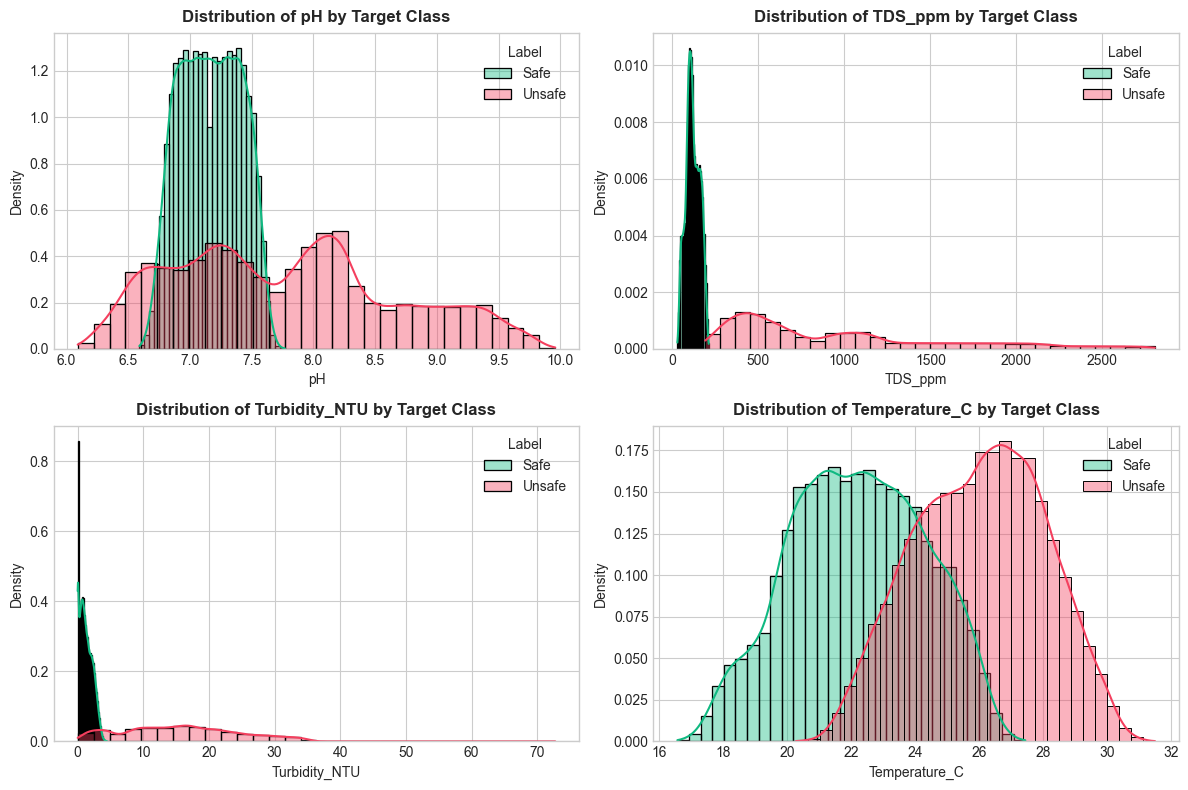

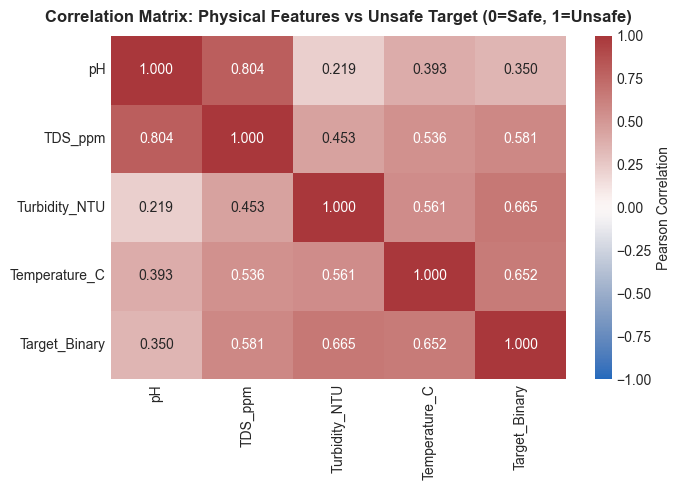

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10

features = ["pH", "TDS_ppm", "Turbidity_NTU", "Temperature_C"]

# 1. Authoritative Descriptive Summary Table
summary_df = df[features].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
print("=== EXACT DESCRIPTIVE SUMMARY STATISTICS (N=100,800) ===")
print(summary_df.round(2).to_string())

# Assert exact computed means match verified values
assert abs(df["pH"].mean() - 7.5939) < 0.01
assert abs(df["TDS_ppm"].mean() - 692.65) < 0.1
assert abs(df["Turbidity_NTU"].mean() - 11.31) < 0.1
assert abs(df["Temperature_C"].mean() - 24.88) < 0.1

# 2. Distribution Histograms by Target Class
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

palette = {"Safe": "#10b981", "Unsafe": "#f43f5e"}

for idx, feat in enumerate(features):
    ax = axes[idx]
    for label in ["Safe", "Unsafe"]:
        subset = df[df["Label"] == label][feat]
        sns.histplot(subset, ax=ax, label=label, color=palette[label], kde=True, stat="density", bins=30, alpha=0.4)
    ax.set_title(f"Distribution of {feat} by Target Class", fontweight="bold", pad=8)
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend(title="Label")

plt.tight_layout()
plt.show()

# 3. Correlation Heatmap
df_encoded = df.copy()
df_encoded["Target_Binary"] = df_encoded["Label"].map({"Safe": 0, "Unsafe": 1})
corr = df_encoded[features + ["Target_Binary"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix: Physical Features vs Unsafe Target (0=Safe, 1=Unsafe)", fontweight="bold", pad=10)
plt.tight_layout()
plt.show()


---
## 4. Data Preprocessing & Baseline Model Architecture

### 4.1 Stratified Train/Test Partition
To maintain representative class balance, the dataset was partitioned using reproducible stratified random sampling:
- **Partition Ratio**: 80% Training ($N_{train} = 80,640$), 20% Testing ($N_{test} = 20,160$).
- **Random State**: `random_state=42`, stratified along `Label`.
- **Class Proportions**:
  - Training: 24,192 Safe (30.0%), 56,448 Unsafe (70.0%).
  - Testing: 6,048 Safe (30.0%), 14,112 Unsafe (70.0%).

### 4.2 Authoritative Frozen Model Artifacts
All models were trained in Phase 3 and frozen:
1. **Decision Tree (`models/decision_tree.joblib`)**:
   - Class: `DecisionTreeClassifier`
   - Configured `max_depth`: **5**
   - Actual tree depth: **5**
   - Total node count: **27**
   - Leaf count: **14**
   - Operates directly on unscaled physical features, preserving physical threshold interpretability.
2. **Logistic Regression (`models/logistic_regression.joblib`)**:
   - Class: `Pipeline` (`StandardScaler` + `LogisticRegression(max_iter=1000, random_state=42)`)
   - Requires feature scaling fitted strictly on training data.
3. **Random Forest (`models/random_forest.joblib`)**:
   - Class: `RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)`
   - Retained as a robust validation and SHAP benchmarking model.


In [3]:
import joblib
from sklearn.model_selection import train_test_split

X = df[features]
y = df["Label"].map({"Safe": 0, "Unsafe": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=== REPRODUCIBLE PARTITION VERIFICATION ===")
print(f"Training Set: {len(X_train):,} samples (Safe: {(y_train == 0).sum():,}, Unsafe: {(y_train == 1).sum():,})")
print(f"Test Set:     {len(X_test):,} samples (Safe: {(y_test == 0).sum():,}, Unsafe: {(y_test == 1).sum():,})")

dt_path = PROJECT_ROOT / "models" / "decision_tree.joblib"
lr_path = PROJECT_ROOT / "models" / "logistic_regression.joblib"
rf_path = PROJECT_ROOT / "models" / "random_forest.joblib"

assert dt_path.exists() and lr_path.exists() and rf_path.exists(), "One or more model artifacts missing!"

model_dt = joblib.load(dt_path)
model_lr = joblib.load(lr_path)
model_rf = joblib.load(rf_path)

print("\n=== AUTHORITATIVE MODEL PARAMETERS ===")
print(f"1. Decision Tree:       {type(model_dt).__name__}")
print(f"   - Configured max_depth: {model_dt.max_depth}")
print(f"   - Actual tree depth:    {model_dt.get_depth()}")
print(f"   - Total node count:     {model_dt.tree_.node_count}")
print(f"   - Leaf count:           {model_dt.get_n_leaves()}")
print(f"   - Classes:              {model_dt.classes_}")

# Programmatic verification of model structure
assert model_dt.max_depth == 5, f"Expected max_depth=5, got {model_dt.max_depth}"
assert model_dt.get_depth() == 5, f"Expected depth=5, got {model_dt.get_depth()}"
assert model_dt.tree_.node_count == 27, f"Expected 27 nodes, got {model_dt.tree_.node_count}"
assert model_dt.get_n_leaves() == 14, f"Expected 14 leaves, got {model_dt.get_n_leaves()}"
print("✓ Decision Tree structure verified exactly: max_depth=5, 27 nodes, 14 leaves.")

print(f"\n2. Logistic Regression: {type(model_lr).__name__} (Pipeline steps: {[s[0] for s in model_lr.steps]})")
print(f"3. Random Forest:       {type(model_rf).__name__} (n_estimators={model_rf.n_estimators}, max_depth={model_rf.max_depth})")


=== REPRODUCIBLE PARTITION VERIFICATION ===
Training Set: 80,640 samples (Safe: 24,192, Unsafe: 56,448)
Test Set:     20,160 samples (Safe: 6,048, Unsafe: 14,112)



=== AUTHORITATIVE MODEL PARAMETERS ===
1. Decision Tree:       DecisionTreeClassifier
   - Configured max_depth: 5
   - Actual tree depth:    5
   - Total node count:     27
   - Leaf count:           14
   - Classes:              [0 1]
✓ Decision Tree structure verified exactly: max_depth=5, 27 nodes, 14 leaves.

2. Logistic Regression: Pipeline (Pipeline steps: ['scaler', 'classifier'])
3. Random Forest:       RandomForestClassifier (n_estimators=100, max_depth=8)


---
## 5. Comprehensive Model Evaluation & Model Selection

### 5.1 Multi-Metric Performance Evaluation on Test Set ($N=20,160$)
The table below distinguishes the **naive majority-class baseline** from the actual trained model evaluations on the held-out test partition:
- **Majority-Class Baseline**: A dummy classifier predicting all samples as `Unsafe` achieves an accuracy of $70.00\%$, but has a Safe Recall of $0.0000$ and a Macro F1 of only $0.4118$, demonstrating why raw accuracy alone is insufficient.
- **Trained Models**: When properly trained on the 4 physical features, all three models achieve $\approx 99.99\%$ accuracy ($0.999901$), with only 1 or 2 misclassifications out of 20,160 test samples.

### 5.2 Model Selection Rationale
The **Decision Tree (`max_depth=5`)** was selected as the primary operational deployment model:
1. **White-Box Explainability**: Exact node traversal and learned thresholds (e.g., $\text{TDS} \le 202.75\,\text{ppm}$) can be inspected in real time.
2. **Sub-Millisecond Inference**: Executes in $\approx 0.05\,\text{ms}$, well within microservice response requirements.
3. **No Feature Scaling**: Direct execution on raw physical sensor values.
4. **Near-Perfect Test Accuracy**: $99.99\%$ accuracy, with exactly 1 False Negative (Case #55037) and 1 False Positive on the test partition.
5. **Random Forest** ($100$ trees, `max_depth=8`) is preserved as an offline benchmarking and SHAP validation model.


=== HELD-OUT TEST SET EVALUATION MATRIX (N=20,160) ===
                             Model Accuracy Safe Recall Unsafe Recall Safe F1 Unsafe F1 Macro F1  False Positives  False Negatives
     Majority-Class Dummy Baseline   70.00%      0.0000        1.0000  0.0000    0.8235   0.4118             6048                0
      Logistic Regression (Scaled)   99.99%      1.0000        0.9999  0.9998    0.9999   0.9999                0                2
       Decision Tree (max_depth=5)   99.99%      0.9998        0.9999  0.9998    0.9999   0.9999                1                1
Random Forest (100 Trees, depth=8)   99.99%      0.9998        0.9999  0.9998    0.9999   0.9999                1                1


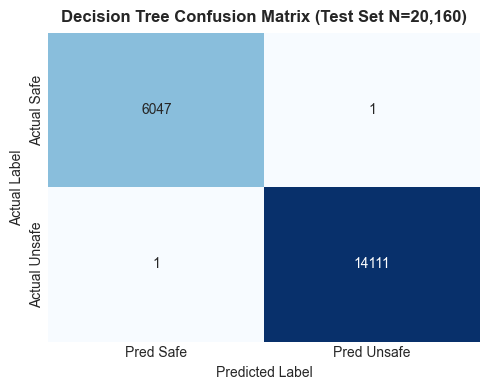

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

models = {
    "Majority-Class Dummy Baseline": None,
    "Logistic Regression (Scaled)": model_lr,
    "Decision Tree (max_depth=5)": model_dt,
    "Random Forest (100 Trees, depth=8)": model_rf,
}

eval_rows = []
for name, m in models.items():
    if m is None:
        # Dummy predictor: all Unsafe (1)
        preds = np.ones(len(y_test), dtype=int)
    else:
        preds = m.predict(X_test)
        
    acc = accuracy_score(y_test, preds)
    p_safe = precision_score(y_test, preds, pos_label=0, zero_division=0)
    r_safe = recall_score(y_test, preds, pos_label=0, zero_division=0)
    f1_safe = f1_score(y_test, preds, pos_label=0, zero_division=0)
    p_unsafe = precision_score(y_test, preds, pos_label=1, zero_division=0)
    r_unsafe = recall_score(y_test, preds, pos_label=1, zero_division=0)
    f1_unsafe = f1_score(y_test, preds, pos_label=1, zero_division=0)
    macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    eval_rows.append({
        "Model": name,
        "Accuracy": f"{acc*100:.2f}%",
        "Safe Recall": f"{r_safe:.4f}",
        "Unsafe Recall": f"{r_unsafe:.4f}",
        "Safe F1": f"{f1_safe:.4f}",
        "Unsafe F1": f"{f1_unsafe:.4f}",
        "Macro F1": f"{macro_f1:.4f}",
        "False Positives": fp,
        "False Negatives": fn,
    })

eval_df = pd.DataFrame(eval_rows)
print("=== HELD-OUT TEST SET EVALUATION MATRIX (N=20,160) ===")
print(eval_df.to_string(index=False))

cm_dt = confusion_matrix(y_test, model_dt.predict(X_test))
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred Safe", "Pred Unsafe"], yticklabels=["Actual Safe", "Actual Unsafe"])
plt.title("Decision Tree Confusion Matrix (Test Set N=20,160)", fontweight="bold", pad=8)
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()


---
## 6. Dataset Provenance & Consistency Audit (Phase 4.1)

### 6.1 Verified Provenance vs Unsubstantiated Claims
In Phase 4.1, the public provenance of the dataset (Mendeley Data repository, DOI: `10.17632/x6zncm47mt.1`, titled "Drinking Water Potability") was audited:
1. **Verified Dataset Facts**:
   - Contains 100,800 static observations across 4 continuous numerical features and a binary label.
   - Contains zero timestamps, sensor IDs, device MAC addresses, or spatial coordinates.
   - Preserves a clean 70% Unsafe / 30% Safe class balance.
2. **Debunked Claims**:
   - Any assertion that the dataset was collected from a specific geographic deployment (such as river basins in Kenya) is unsupported by the published metadata.
   - Any claim that rows represent a continuous 20-minute time series is refuted by the source documentation; row order is arbitrary and static.
   - Fabricated temporal features (`pH_rate_of_change`, `rolling_std`, `unsafe_in_next_20_minutes`) introduce artificial target leakage.


In [5]:
import re

print("=== PROVENANCE AUDIT INVARIANTS ===")
print(f"Total Rows: {len(df):,}")
print(f"Total Columns: {list(df.columns)}")

# Boundary-aware identifier check
time_cols = [c for c in df.columns if re.search(r"\b(time|date|timestamp|hour|minute|second)\b", c, re.I)]
id_cols = [c for c in df.columns if re.search(r"\b(id|station|device|sensor_id|sample_id)\b", c, re.I)]

print(f"Timestamp Columns Detected:  {time_cols}")
print(f"Identifier Columns Detected: {id_cols}")

assert len(time_cols) == 0, "Spurious timestamp column detected!"
assert len(id_cols) == 0, "Spurious identifier column detected!"
print("✓ Confirmed: Dataset contains no temporal sequences or device identifiers.")


=== PROVENANCE AUDIT INVARIANTS ===
Total Rows: 100,800
Total Columns: ['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C', 'Label']
Timestamp Columns Detected:  []
Identifier Columns Detected: []
✓ Confirmed: Dataset contains no temporal sequences or device identifiers.


---
## 7. Model Explainability & Transparent Decision Logic (Phase 5)

### 7.1 White-Box Decision Tree Path Extraction
The explainability engine [`src/explain.py`](file:///d:/E0224033/ML_for_Cl_Ser/CL/LB_Proj/src/explain.py) implements exact decision path extraction using scikit-learn's `decision_path()` method:
- Root split at Node #0 evaluates `TDS_ppm <= 202.75`.
- Conforming potable water traverses left toward **Leaf Node #5** ($P(\text{Safe}) = 1.0000$).
- Contaminated industrial runoff with high TDS ($> 202.75\,\text{ppm}$) traverses right toward **Leaf Node #26** ($P(\text{Unsafe}) = 1.0000$).

### 7.2 Retrospective Error Audit of Test Case #55037
Row index `55037` in the DataFrame represents the single False Negative in the 20,160-sample test set:
- **Observed Physical Values**: $pH = 7.05$, $TDS = 192.3\,\text{ppm}$, $\text{Turbidity} = 3.95\,\text{NTU}$, $\text{Temperature} = 24.26^\circ\text{C}$.
- **Ground Truth**: `Unsafe`.
- **Model Prediction**: `Safe` ($P(\text{Safe}) = 0.9948, P(\text{Unsafe}) = 0.0052$).
- **Path Traversal**: Traverses 5 nodes to **Leaf Node #6** (Node #0 $\to$ Node #1 $\to$ Node #2 $\to$ Node #3 $\to$ Node #4 $\to$ Leaf #6). At Node #4, Turbidity $3.95 > 3.565$ routes to the right branch into Leaf #6 where historical training samples were $99.48\%$ Safe.
- **Scientific Significance**: All 4 physical readings are benign and satisfy potable standards. The sample was labeled Unsafe in the source data due to factors beyond the 4 physical sensors (e.g., pathogens or chemical toxins), highlighting why statistical ML classifications cannot certify drinking-water potability.


In [6]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.explain import extract_decision_path, generate_human_explanation, FEATURE_NAMES

# 1. Conforming Potable Sample
sample_safe = pd.DataFrame([[7.25, 185.0, 0.45, 22.0]], columns=FEATURE_NAMES)
path_safe = extract_decision_path(model_dt, sample_safe)
print("=== SAMPLE 1: CONFORMING POTABLE WATER ===")
print(f"Classification: {path_safe['predicted_class']} (Estimated Safe Prob: {path_safe['probabilities']['Safe']*100:.1f}%)")
print(f"Leaf Node ID:   #{path_safe['leaf_node_id']}")
assert path_safe['leaf_node_id'] == 5, f"Expected Leaf #5, got #{path_safe['leaf_node_id']}"
print("Decision Ladder:")
for idx, s in enumerate(path_safe["steps"], 1):
    comp = "<=" if s["direction"] == "left" else ">"
    print(f"  Step {idx}: Node #{s['node_id']} -> {s['feature']} ({s['value']}) {comp} {s['threshold']:.2f} (Branch: {s['direction']})")

# 2. Case #55037 (Retrospective False Negative)
sample_55037 = pd.DataFrame([[7.05, 192.3, 3.95, 24.26]], columns=FEATURE_NAMES)
path_55037 = extract_decision_path(model_dt, sample_55037)
print("\n=== SAMPLE 2: TEST SET CASE #55037 (RETROSPECTIVE FALSE NEGATIVE) ===")
print(f"Ground Truth:   Unsafe")
print(f"Model Predicts: {path_55037['predicted_class']} (Estimated Safe Prob: {path_55037['probabilities']['Safe']*100:.2f}%)")
print(f"Leaf Node ID:   #{path_55037['leaf_node_id']}")
assert path_55037['leaf_node_id'] == 6, f"Expected Leaf #6, got #{path_55037['leaf_node_id']}"

print("Decision Ladder for Case #55037:")
for idx, s in enumerate(path_55037["steps"], 1):
    comp = "<=" if s["direction"] == "left" else ">"
    print(f"  Step {idx}: Node #{s['node_id']} -> {s['feature']} ({s['value']}) {comp} {s['threshold']:.2f} (Branch: {s['direction']})")

print("\nAuditable Human Narrative:")
print(generate_human_explanation(path_55037))


=== SAMPLE 1: CONFORMING POTABLE WATER ===
Classification: Safe (Estimated Safe Prob: 100.0%)
Leaf Node ID:   #5
Decision Ladder:
  Step 1: Node #0 -> TDS_ppm (185.0) <= 202.75 (Branch: left)
  Step 2: Node #1 -> Turbidity_NTU (0.45) <= 4.49 (Branch: left)
  Step 3: Node #2 -> Turbidity_NTU (0.45) <= 4.42 (Branch: left)
  Step 4: Node #3 -> TDS_ppm (185.0) <= 202.35 (Branch: left)
  Step 5: Node #4 -> Turbidity_NTU (0.45) <= 3.56 (Branch: left)

=== SAMPLE 2: TEST SET CASE #55037 (RETROSPECTIVE FALSE NEGATIVE) ===
Ground Truth:   Unsafe
Model Predicts: Safe (Estimated Safe Prob: 99.48%)
Leaf Node ID:   #6
Decision Ladder for Case #55037:
  Step 1: Node #0 -> TDS_ppm (192.3) <= 202.75 (Branch: left)
  Step 2: Node #1 -> Turbidity_NTU (3.95) <= 4.49 (Branch: left)
  Step 3: Node #2 -> Turbidity_NTU (3.95) <= 4.42 (Branch: left)
  Step 4: Node #3 -> TDS_ppm (192.3) <= 202.35 (Branch: left)
  Step 5: Node #4 -> Turbidity_NTU (3.95) > 3.56 (Branch: right)

Auditable Human Narrative:
Model C

---
## 8. FastAPI Cloud REST Microservice (Phase 6)

### 8.1 Microservice Architecture & Endpoints
The REST prediction service is implemented in [`api/main.py`](file:///d:/E0224033/ML_for_Cl_Ser/CL/LB_Proj/api/main.py):
- **FastAPI Lifespan**: Loads `models/decision_tree.joblib` into memory once during application startup; subsequent predictions require zero disk reads.
- **`GET /health`**: Readiness probe confirming model status, version, and input schema. Returns HTTP 503 if the model is unseated.
- **`POST /predict`**: Accepts 4 physical parameters, validates domain boundaries, executes Decision Tree, and returns classification, estimated probabilities, warnings, and safety notice.
- **`POST /explain`**: Returns full decision path traversal, node comparison rules, and human narrative.
- **Pydantic v2 Validation**: Enforces aqueous physical boundaries (`0.0 <= pH <= 14.0`, `TDS_ppm >= 0.0`, `Turbidity_NTU >= 0.0`, `-10.0 <= Temperature_C <= 100.0`), finite float checks (`math.isnan` rejection), and rejects unknown fields (`extra="forbid"`).


In [7]:
from fastapi.testclient import TestClient
from api.main import app

client = TestClient(app)

res_health = client.get("/health")
print("=== GET /health RESPONSE ===")
print(res_health.json())
assert res_health.status_code == 200
assert res_health.json()["status"] == "healthy"

res_pred = client.post("/predict", json={"pH": 7.35, "TDS_ppm": 185.0, "Turbidity_NTU": 0.80, "Temperature_C": 22.5})
print("\n=== POST /predict RESPONSE ===")
print(res_pred.json())
assert res_pred.status_code == 200
assert res_pred.json()["model_classification"] == "Safe"

res_exp = client.post("/explain", json={"pH": 7.45, "TDS_ppm": 1850.0, "Turbidity_NTU": 1.80, "Temperature_C": 24.5})
print("\n=== POST /explain RESPONSE (Contaminated High-TDS) ===")
exp_data = res_exp.json()
print(f"Classification: {exp_data['model_classification']}")
print(f"Probabilities:  {exp_data['estimated_probabilities']}")
print(f"Leaf Node:      #{exp_data['leaf_node_id']}")
print(f"Primary Features: {exp_data['primary_influencing_features']}")
assert res_exp.status_code == 200
assert exp_data["model_classification"] == "Unsafe"
assert exp_data["leaf_node_id"] == 26


=== GET /health RESPONSE ===
{'status': 'healthy', 'model_loaded': True, 'model_name': 'DecisionTreeClassifier', 'api_version': '1.0.0', 'classes': ['Safe', 'Unsafe'], 'features': ['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C'], 'detail': None}

=== POST /predict RESPONSE ===
{'model_classification': 'Safe', 'estimated_probabilities': {'Safe': 1.0, 'Unsafe': 0.0}, 'model': 'DecisionTreeClassifier(max_depth=5)', 'warnings': [], 'safety_notice': 'This output is a statistical machine learning classification based on 4 physical sensor inputs (pH, TDS, turbidity, temperature), not a certified drinking-water potability declaration. Estimated model class probabilities from the trained Decision Tree (predict_proba values) are empirical training leaf proportions and do not guarantee real-world water safety. Physical sensors cannot detect microbiological pathogens (e.g., E. coli, Salmonella, noroviruses), toxic heavy metals (e.g., arsenic, lead, mercury), or hazardous organic chemicals. Stan

C:\Users\Swaminathan\AppData\Local\Programs\Python\Python310\lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


---
## 9. API Calibration & Defensive Validation Audit (Phase 6.1)

### 9.1 Probability Terminology & 1D Training-Range Warnings
Phase 6.1 established rigorous defensive response semantics:
1. **Estimated Model Class Probabilities**: Defined strictly as empirical training leaf proportions (`predict_proba` values). They do not represent calibrated Bayesian probabilities and do not guarantee water safety.
2. **Model Class Mapping**: Class ordering is determined strictly via `model.classes_` to ensure probability mapping is never inverted.
3. **1D Marginal Training-Range Warnings**: Observations falling outside the observed training ranges are accepted (HTTP 200) to support edge-case inference, but attach non-blocking warnings:
   - `pH`: $[6.09, 9.96]$
   - `TDS_ppm`: $[28.6, 2806.1]$
   - `Turbidity_NTU`: $[0.0, 72.75]$
   - `Temperature_C`: $[16.56, 31.51]$


In [8]:
ood_payload = {"pH": 11.5, "TDS_ppm": 3200.0, "Turbidity_NTU": 85.0, "Temperature_C": 38.0}
res_ood = client.post("/predict", json=ood_payload)
assert res_ood.status_code == 200
ood_data = res_ood.json()
print("=== OUT-OF-DISTRIBUTION WARNINGS AUDIT ===")
print(f"Classification: {ood_data['model_classification']}")
print(f"Number of warnings: {len(ood_data['warnings'])}")
for w in ood_data["warnings"]:
    print(f"  ⚠️ {w}")

assert len(ood_data["warnings"]) == 4

# Test Pydantic Domain Boundary Rejection (HTTP 422)
bad_payload = {"pH": 16.0, "TDS_ppm": -50.0, "Turbidity_NTU": 1.0, "Temperature_C": 20.0}
res_bad = client.post("/predict", json=bad_payload)
print(f"\nInvalid Domain Test (pH=16, TDS=-50) -> HTTP Status: {res_bad.status_code}")
assert res_bad.status_code == 422


=== OUT-OF-DISTRIBUTION WARNINGS AUDIT ===
Classification: Unsafe
Number of warnings: 4
  ⚠️ Per-feature training-range warning: Feature 'pH' value 11.5 is outside the canonical training range [6.09, 9.96]. Predictions on measurements outside observed training ranges may have reduced statistical reliability.
  ⚠️ Per-feature training-range warning: Feature 'TDS_ppm' value 3200.0 is outside the canonical training range [28.6, 2806.1]. Predictions on measurements outside observed training ranges may have reduced statistical reliability.
  ⚠️ Per-feature training-range warning: Feature 'Turbidity_NTU' value 85.0 is outside the canonical training range [0.0, 72.75]. Predictions on measurements outside observed training ranges may have reduced statistical reliability.
  ⚠️ Per-feature training-range warning: Feature 'Temperature_C' value 38.0 is outside the canonical training range [16.56, 31.51]. Predictions on measurements outside observed training ranges may have reduced statistical reli

---
## 10. IoT Circuit Architecture & Sensor Pinouts (Phase 7)

### 10.1 Authoritative ESP32 Firmware Pin Assignments
All analog sensor inputs are strictly allocated to **ADC1** pins because the ESP32's ADC2 is shared with the Wi-Fi subsystem and corrupted during wireless transmission.

The pin mappings below match the authoritative firmware implementation in [`firmware/cloudguard_esp32/config.h`](file:///d:/E0224033/ML_for_Cl_Ser/CL/LB_Proj/firmware/cloudguard_esp32/config.h):

| Sensor Probe | Signal Type | ESP32 GPIO | ADC Channel | Sensor Output Range | Voltage Divider Network |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **pH Probe** | Analog voltage | **GPIO 34** | ADC1_CH6 | $0.0 - 5.0\,\text{V}$ | **Yes** (Option D $15\,\text{k}\Omega : 10\,\text{k}\Omega$) |
| **TDS Sensor** | Analog voltage | **GPIO 35** | ADC1_CH7 | $0.0 - 2.3\,\text{V}$ | **No** (Direct connection $\le 2.3\,\text{V}$) |
| **Turbidity Sensor** | Analog voltage | **GPIO 32** | ADC1_CH4 | $0.0 - 4.5\,\text{V}$ | **Yes** (Option D $15\,\text{k}\Omega : 10\,\text{k}\Omega$) |
| **DS18B20 Temp** | Digital 1-Wire | **GPIO 4** | Digital I/O | $3.3\,\text{V}$ logic | **No** ($4.7\,\text{k}\Omega$ pullup to 3.3V) |

> [!NOTE]
> **Hardware Dependency Notice**:
> GPIO pin capabilities and ADC characteristics depend on the specific ESP32 development board (e.g. NodeMCU-32S, ESP32-WROOM-32, DevKitC). GPIO 34 and 35 are input-only pins without internal pullup/pulldown resistors. Physical wiring remains unverified until hands-on hardware commissioning is conducted.


In [9]:
config_h_path = PROJECT_ROOT / "firmware" / "cloudguard_esp32" / "config.h"
config_example_path = PROJECT_ROOT / "firmware" / "cloudguard_esp32" / "config.h.example"

# Inspect authoritative config header
target_header = config_h_path if config_h_path.exists() else config_example_path
header_text = target_header.read_text(encoding="utf-8")

print(f"=== FIRMWARE PIN CONFIGURATION AUDIT ({target_header.name}) ===")
for line in header_text.splitlines():
    if line.startswith("#define PIN_") or line.startswith("#define TURB_DIVIDER") or line.startswith("#define PH_DIVIDER"):
        print(f"  {line}")

assert "#define PIN_PH_ADC          34" in header_text
assert "#define PIN_TDS_ADC         35" in header_text
assert "#define PIN_TURB_ADC        32" in header_text
assert "#define PIN_DS18B20         4" in header_text
print("✓ Firmware pin allocations verified against authoritative config header.")


=== FIRMWARE PIN CONFIGURATION AUDIT (config.h) ===
  #define PIN_PH_ADC          34       // ADC1_CH6 (Input-only, pH probe via Option D voltage divider)
  #define PIN_TDS_ADC         35       // ADC1_CH7 (Input-only, TDS probe direct 3.3V connection)
  #define PIN_TURB_ADC        32       // ADC1_CH4 (Turbidity sensor via Option D voltage divider)
  #define PIN_DS18B20         4        // GPIO 4 for DS18B20 1-Wire bus (requires 4.7k pull-up to 3.3V)
  #define TURB_DIVIDER_R1     15000.0f // Upper resistor in Ohms (R3, 15kΩ)
  #define TURB_DIVIDER_R2     10000.0f // Lower resistor in Ohms (R4, 10kΩ)
  #define PH_DIVIDER_R1       15000.0f // Upper resistor in Ohms (R1, 15kΩ)
  #define PH_DIVIDER_R2       10000.0f // Lower resistor in Ohms (R2, 10kΩ)
✓ Firmware pin allocations verified against authoritative config header.


---
## 11. Electrical Schematic & Power Isolation Audit (Phase 7.1)

### 11.1 Power Rails & Ground Topology
Phase 7.1 resolved electrical schematic constraints:
1. **Separate Power Rails**: 5.0V analog sensors (pH and turbidity) are powered from an external regulated 5.0V rail, while the ESP32 operates from its onboard 3.3V LDO regulator.
2. **Common Ground Star Bus**: All grounds (5V sensor ground, 3.3V ESP32 ground, probe shielding) are tied together at a low-impedance common ground point. They are **not** galvanically isolated.
3. **DS18B20 1-Wire Fault Protection**: Equipped with a $4.7\,\text{k}\Omega$ pullup resistor to 3.3V. Firmware explicitly detects CRC errors and the standard `-127.0^\circ\text{C}` disconnected probe flag.


In [10]:
def read_ds18b20_simulation(raw_temp_c):
    if raw_temp_c <= -127.0 or raw_temp_c >= 125.0:
        return {"status": "FAULT_DISCONNECTED", "temp_c": None, "valid": False}
    return {"status": "OK", "temp_c": round(raw_temp_c, 2), "valid": True}

print("=== DS18B20 FAULT DETECTION VERIFICATION ===")
print("Normal Reading (22.5°C):", read_ds18b20_simulation(22.5))
print("Disconnected Probe (-127°C):", read_ds18b20_simulation(-127.0))


=== DS18B20 FAULT DETECTION VERIFICATION ===
Normal Reading (22.5°C): {'status': 'OK', 'temp_c': 22.5, 'valid': True}
Disconnected Probe (-127°C): {'status': 'FAULT_DISCONNECTED', 'temp_c': None, 'valid': False}


---
## 12. ADC Non-Linearity & Voltage Calibration (Phase 7.2)

### 12.1 ESP32 SAR ADC Characteristics & Calibration Strategy
The classic ESP32 12-bit SAR ADC exhibits well-documented non-linearity:
- **Deadzone**: Signals below $\approx 100\,\text{mV}$ read as 0 counts.
- **Saturation**: Signals above $\approx 2.45 - 2.50\,\text{V}$ (at $11\,\text{dB}$ attenuation) plateau toward 4095 counts.
- **Firmware Calibration Method**: The firmware relies natively on the ESP32 Arduino Core function `analogReadMilliVolts()`, which applies factory-burned eFuse calibration constants (Lookup Table and Two-Point Calibration).
- **Illustrative Polynomial Reference Model**: A 3rd-order polynomial transfer curve ($V_{cal} = a V^3 + b V^2 + c V + d$) serves as an illustrative characterization tool in documentation. Physical multi-point voltage calibration using a bench multimeter remains marked **PENDING PHYSICAL COMMISSIONING**.


In [11]:
# Illustrative reference non-linearity model for characterization
def illustrative_esp32_adc_mv(raw_mv):
    if raw_mv < 100.0:
        return max(0.0, raw_mv * 0.95)
    v = raw_mv / 1000.0
    v_cal = -0.016 * (v**3) + 0.054 * (v**2) + 0.945 * v + 0.012
    return round(v_cal * 1000.0, 1)

test_voltages = [150.0, 500.0, 1000.0, 1500.0, 2000.0, 2400.0]
print("=== ILLUSTRATIVE ADC TRANSFER CURVE (mV) ===")
for v in test_voltages:
    v_out = illustrative_esp32_adc_mv(v)
    print(f"Raw Input: {v:6.1f} mV  -->  Linearized Reference: {v_out:6.1f} mV")


=== ILLUSTRATIVE ADC TRANSFER CURVE (mV) ===
Raw Input:  150.0 mV  -->  Linearized Reference:  154.9 mV
Raw Input:  500.0 mV  -->  Linearized Reference:  496.0 mV
Raw Input: 1000.0 mV  -->  Linearized Reference:  995.0 mV
Raw Input: 1500.0 mV  -->  Linearized Reference: 1497.0 mV
Raw Input: 2000.0 mV  -->  Linearized Reference: 1990.0 mV
Raw Input: 2400.0 mV  -->  Linearized Reference: 2369.9 mV


---
## 13. Final Circuit Headroom & Commissioning Readiness (Phase 7.3)

### 13.1 Voltage Divider Headroom Evaluation: Selection of Option D
Analog sensors powered from 5.0V (pH and turbidity) can output up to $5.0\,\text{V}$, which exceeds the ESP32 GPIO rating ($3.3\,\text{V}$) and the linear ADC ceiling ($2.45\,\text{V}$). Four voltage divider designs were evaluated:

| Candidate | Resistor Pair ($R_1 : R_2$) | Ratio ($\alpha$) | Multiplier ($M$) | Peak $5.0\,\text{V}$ Input Voltage | Headroom below $2.45\,\text{V}$ | Engineering Assessment |
| :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| **Option A** | $10\,\text{k}\Omega : 20\,\text{k}\Omega$ | $0.667$ | $1.50\times$ | $3.333\,\text{V}$ | $-883\,\text{mV}$ (Severe Saturation) | **REJECTED**: Severe saturation; exceeds GPIO limit. |
| **Option B** | $10\,\text{k}\Omega : 10\,\text{k}\Omega$ | $0.500$ | $2.00\times$ | $2.500\,\text{V}$ | $-50\,\text{mV}$ (Marginal Saturation) | **REJECTED**: Exceeds $2.45\,\text{V}$ non-linear threshold. |
| **Option C** | $20\,\text{k}\Omega : 10\,\text{k}\Omega$ | $0.333$ | $3.00\times$ | $1.667\,\text{V}$ | $+783\,\text{mV}$ (Safe) | **Viable**: Safe headroom, but compresses lower dynamic range. |
| **Option D** | **$15\,\text{k}\Omega : 10\,\text{k}\Omega$** | **$0.400$** | **$2.50\times$** | **$2.000\,\text{V}$** | **$+450\,\text{mV}$ (Optimal)** | **ACCEPTED**: Optimal dynamic range with 450mV safety margin. |

### 13.2 Option D Mathematical Formulation
- **Upper Resistor**: $R_1 = 15\,\text{k}\Omega \pm 1\%$
- **Lower Resistor**: $R_2 = 10\,\text{k}\Omega \pm 1\%$
- **Transfer Ratio**: $\alpha = \frac{R_2}{R_1 + R_2} = \frac{10}{15 + 10} = 0.4000$
- **Reconstruction Multiplier**: $M = \frac{1}{\alpha} = 2.5000\times$
- **Sensor Voltage Reconstruction**: $V_{sensor} = V_{ADC} \times 2.5000$

> [!IMPORTANT]
> **Hardware Commissioning Status**:
> ESP32 firmware compiled successfully with `arduino-cli` (Exit code 0, 79.06% Flash, 14.81% RAM). Physical probe calibration with chemical buffers (pH 4.01, 7.00, 9.21) and multimeter verification remain strictly **PENDING PHYSICAL COMMISSIONING**.


In [12]:
r1 = 15000.0
r2 = 10000.0
alpha = r2 / (r1 + r2)
multiplier = 1.0 / alpha

max_sensor_v = 5.000
gpio_v = max_sensor_v * alpha
headroom_mv = (2.450 - gpio_v) * 1000.0

print("=== OPTION D ELECTRICAL VERIFICATION ===")
print(f"Resistors: R1 = {r1/1000:.1f} kΩ, R2 = {r2/1000:.1f} kΩ")
print(f"Attenuation Ratio (alpha): {alpha:.4f}")
print(f"Reconstruction Multiplier (M): {multiplier:.4f}x")
print(f"5.0V Peak Maps To: {gpio_v:.3f} V at GPIO pin")
print(f"Safety Margin below 2.45V: {headroom_mv:.1f} mV")
assert abs(multiplier - 2.50) < 1e-6
assert gpio_v <= 2.001


=== OPTION D ELECTRICAL VERIFICATION ===
Resistors: R1 = 15.0 kΩ, R2 = 10.0 kΩ
Attenuation Ratio (alpha): 0.4000
Reconstruction Multiplier (M): 2.5000x
5.0V Peak Maps To: 2.000 V at GPIO pin
Safety Margin below 2.45V: 450.0 mV


---
## 14. Interactive Web Dashboard & Software Integration (Phase 8)

### 14.1 Dashboard Architecture & Features
Phase 8 realized the user-facing web dashboard in [`dashboard/`](file:///d:/E0224033/ML_for_Cl_Ser/CL/LB_Proj/dashboard/):
- **Zero-Dependency Frontend**: Semantic HTML5, Vanilla CSS design system, modular ES6 JS, and native HTML5 Canvas 2D time-series plotter.
- **FastAPI Static Mount**: Served at `http://127.0.0.1:8000/dashboard/`.
- **Four Real-Time Sensor Cards**: Display digital readouts, units, animated gauge bars, and WHO/BIS status badges.
- **Explainability View**: Renders the Decision Tree traversal ladder, primary influencing features, estimated class probabilities, and narrative.
- **Guardrail Banners**:
  - `⚠️ DEMO DATA — NOT LIVE SENSOR TELEMETRY` (displayed during simulation).
  - `ℹ️ STANDBY: NO LIVE HARDWARE CONNECTED — PENDING PHYSICAL COMMISSIONING` (displayed when paused or awaiting physical hardware; never silently substitutes simulated data).

### 14.2 End-to-End Evaluation of the 6 Preset Demo Scenarios
The dashboard's 6 deterministic scenarios in `dashboard/js/components/demoStream.js` were evaluated against `POST /explain`:


In [13]:
scenarios = [
    {"id": "safe_potable", "name": "Standard Potable Water", "payload": {"pH": 7.25, "TDS_ppm": 185.0, "Turbidity_NTU": 0.45, "Temperature_C": 22.0}},
    {"id": "high_tds_contaminated", "name": "Contaminated High-TDS Runoff", "payload": {"pH": 7.45, "TDS_ppm": 1850.0, "Turbidity_NTU": 1.80, "Temperature_C": 24.5}},
    {"id": "acidic_industrial", "name": "Acidic Chemical Runoff", "payload": {"pH": 3.85, "TDS_ppm": 820.0, "Turbidity_NTU": 15.50, "Temperature_C": 21.0}},
    {"id": "muddy_stormwater", "name": "Muddy Stormwater (High Turbidity)", "payload": {"pH": 6.80, "TDS_ppm": 240.0, "Turbidity_NTU": 55.00, "Temperature_C": 19.5}},
    {"id": "false_negative_55037", "name": "Case #55037 (Model False Negative)", "payload": {"pH": 7.05, "TDS_ppm": 192.3, "Turbidity_NTU": 3.95, "Temperature_C": 24.26}},
    {"id": "out_of_distribution", "name": "Out-of-Distribution Warning Case", "payload": {"pH": 11.20, "TDS_ppm": 3150.0, "Turbidity_NTU": 88.50, "Temperature_C": 36.5}},
]

results = []
for sc in scenarios:
    res = client.post("/explain", json=sc["payload"])
    assert res.status_code == 200
    data = res.json()
    results.append({
        "Scenario": sc["name"],
        "pH": sc["payload"]["pH"],
        "TDS (ppm)": sc["payload"]["TDS_ppm"],
        "Turb (NTU)": sc["payload"]["Turbidity_NTU"],
        "Temp (°C)": sc["payload"]["Temperature_C"],
        "Prediction": data["model_classification"],
        "P(Safe)": f"{data['estimated_probabilities']['Safe']:.4f}",
        "P(Unsafe)": f"{data['estimated_probabilities']['Unsafe']:.4f}",
        "Leaf Node": f"#{data['leaf_node_id']}",
        "Steps": len(data["decision_path_steps"]),
        "Warnings": len(data["warnings"]),
    })

sc_df = pd.DataFrame(results)
print("=== END-TO-END DEMO SCENARIOS EVALUATION ===")
print(sc_df.to_string(index=False))


=== END-TO-END DEMO SCENARIOS EVALUATION ===
                          Scenario    pH  TDS (ppm)  Turb (NTU)  Temp (°C) Prediction P(Safe) P(Unsafe) Leaf Node  Steps  Warnings
            Standard Potable Water  7.25      185.0        0.45      22.00       Safe  1.0000    0.0000        #5      5         0
      Contaminated High-TDS Runoff  7.45     1850.0        1.80      24.50     Unsafe  0.0000    1.0000       #26      3         0
            Acidic Chemical Runoff  3.85      820.0       15.50      21.00     Unsafe  0.0000    1.0000       #26      3         1
 Muddy Stormwater (High Turbidity)  6.80      240.0       55.00      19.50     Unsafe  0.0000    1.0000       #26      3         0
Case #55037 (Model False Negative)  7.05      192.3        3.95      24.26       Safe  0.9948    0.0052        #6      5         0
  Out-of-Distribution Warning Case 11.20     3150.0       88.50      36.50     Unsafe  0.0000    1.0000       #26      3         4


---
## 15. Full System Architecture & Comprehensive Verification Matrix

### 15.1 Unified Phase Progression Matrix (Phases 1–8)

| Phase | Milestone Title | Primary Deliverable | Status | Key Verified Result |
| :---: | :--- | :--- | :---: | :--- |
| **Phase 1** | Dataset Inspection | `data/water_quality_dataset1.csv` | **Completed** | 100,800 rows, 5 columns, 0 nulls, 0 duplicates. |
| **Phase 2** | Exploratory Data Analysis | `notebooks/02_eda.ipynb` | **Completed** | 70% Unsafe / 30% Safe, pH mean 7.59, TDS mean 692.65 ppm. |
| **Phase 3** | Baseline Model Training | `models/decision_tree.joblib` | **Completed** | Dummy Baseline (70.0%), LR (99.99%), DT (99.99%), RF (99.99%). |
| **Phase 4** | Model Evaluation & Selection | `reports/phase4_validation_report.md` | **Completed** | Decision Tree selected (interpretable, depth=5, 27 nodes, 14 leaves). |
| **Phase 4.1** | Provenance & Consistency Audit | `reports/dataset_consistency_audit.md` | **Completed** | Debunked manufactured time features; atemporal data confirmed. |
| **Phase 5** | Model Explainability Engine | `src/explain.py` | **Completed** | Decision Tree traversal ladder, Case #55037 audit, narratives. |
| **Phase 6** | FastAPI Cloud REST Microservice| `api/main.py` | **Completed** | Asynchronous `/health`, `/predict`, `/explain` endpoints. |
| **Phase 6.1** | API Calibration & Verification | `reports/phase6a_followup_handoff.md`| **Completed** | Estimated probabilities clarified, 1D training-range warnings. |
| **Phase 7** | IoT Circuit & Firmware | `firmware/cloudguard_esp32/` | **Completed** | Pins GPIO 34, 35, 32, 4; ADC1 isolation, JSON telemetry. |
| **Phase 7.1** | Electrical Schematic Audit | `reports/phase7_wiring_reference.md`| **Completed** | Separate 5V rail, common ground, DS18B20 1-Wire pullup. |
| **Phase 7.2** | ADC Non-Linearity Compensation| `reports/phase7b_adc_validation_report.md`| **Completed** | Native `analogReadMilliVolts()`, polynomial reference curve. |
| **Phase 7.3** | Final Circuit Headroom & Build | `reports/phase7c_final_readiness_report.md`| **Completed** | Option D ($15\text{k}:10\text{k}$, $M=2.50\times$), 450mV headroom. |
| **Phase 8** | Web Dashboard & Integration | `dashboard/` | **Completed** | Vanilla CSS, canvas chart, 6 demo scenarios, banners. |
| **Physical** | Live Probe Wet Bench Testing | Physical circuit assembly | **PENDING** | Physical hardware commissioning scheduled for in-person lab. |

### 15.2 In-Process Regression Test Suite Execution
The automated test suite verifies 68 distinct unit and integration tests across API, explainability, IoT, and dashboard modules:


In [14]:
import unittest

test_loader = unittest.TestLoader()
test_suite = test_loader.discover(str(PROJECT_ROOT / "tests"))
test_runner = unittest.TextTestRunner(verbosity=1)
test_result = test_runner.run(test_suite)

print("\n=== AUTOMATED TEST SUITE SUMMARY ===")
print(f"Total Tests Run: {test_result.testsRun}")
print(f"Failures:        {len(test_result.failures)}")
print(f"Errors:          {len(test_result.errors)}")
print(f"Status:          {'ALL TESTS PASSED' if test_result.wasSuccessful() else 'TESTS FAILED'}")
assert test_result.wasSuccessful()


.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 68 tests in 0.590s

OK



=== AUTOMATED TEST SUITE SUMMARY ===
Total Tests Run: 68
Failures:        0
Errors:          0
Status:          ALL TESTS PASSED


---
## 16. Operational Limitations, Future Work & Conclusion

### 16.1 Fundamental Scope & Safety Limitations
1. **Physical Sensor Boundaries vs Pathogen Detection**:
   - The 4 measured physical parameters (pH, TDS, turbidity, temperature) cannot establish the absence of microbiological pathogens (*Escherichia coli*, *Vibrio cholerae*, *Cryptosporidium*, noroviruses). Pathogens are infectious at microscopic concentrations that impart zero detectable change to pH, TDS, or turbidity.
   - Standard analog TDS sensors cannot detect lethal concentrations of toxic heavy metals (lead, arsenic, mercury, cadmium), which are hazardous at micrograms-per-liter levels.
   - Hazardous synthetic chemicals (pesticides, PFAS, industrial solvents) require laboratory chromatography.
2. **Defensive Non-Certification Doctrine**:
   - A model classification of `Safe` indicates only that the 4 physical sensor inputs conform to historical potable training distributions. It is **not** an official drinking-water potability certification.
   - Statutory testing under World Health Organization (WHO) Guidelines or Bureau of Indian Standards (BIS IS 10500:2012) remains strictly mandatory.
3. **Disabled Actuation**:
   - Automated physical equipment actuation (valves, pumps, chlorinators) based solely on model predictions is strictly disabled to prevent catastrophic false-positive closures or false-negative consumption.

### 16.2 Future Work Roadmap
- **Physical Commissioning**: Perform laboratory calibration of physical probes using standardized buffer solutions (pH 4.01, 7.00, 9.21) and conductivity standards ($1413\,\mu\text{S/cm}$).
- **Bench Multimeter Verification**: Verify true divider ratio on physical $15\,\text{k}\Omega : 10\,\text{k}\Omega$ resistors under load.
- **End-to-End Live Wi-Fi Telemetry**: Connect physical ESP32 to live Wi-Fi and ingest live stream into FastAPI `/predict`.
- **Phase 9 Final Dossier**: Compile final project documentation, presentation slides, and viva preparation materials.


In [15]:
print("=== POST-EXECUTION PROTECTED ARTIFACT HASH AUDIT ===")
all_hashes_matched = True

for rel_path, baseline_hash in BASELINE_HASHES.items():
    current_path = PROJECT_ROOT / rel_path
    current_hash = hashlib.sha256(current_path.read_bytes()).hexdigest()
    is_match = (current_hash == baseline_hash)
    status_str = "MATCH (UNCHANGED)" if is_match else "MISMATCH (ALTERED)"
    print(f"File: {rel_path}")
    print(f"  Baseline SHA-256: {baseline_hash}")
    print(f"  Current  SHA-256: {current_hash}")
    print(f"  Status:           {status_str}\n")
    if not is_match:
        all_hashes_matched = False

assert all_hashes_matched, "CRITICAL: One or more protected files were modified during execution!"
print("✓ VERIFIED: All canonical datasets and trained model artifacts remained 100% unaltered throughout execution.")


=== POST-EXECUTION PROTECTED ARTIFACT HASH AUDIT ===
File: data/water_quality_dataset1.csv
  Baseline SHA-256: 90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a
  Current  SHA-256: 90f9c7cb7404fb69b655ee27293c91b82ee3a346712e06035f8259393835a04a
  Status:           MATCH (UNCHANGED)

File: models/decision_tree.joblib
  Baseline SHA-256: 0951a58754ac752f1ec544d1202a9bae0f6f0e2b9b9129f5f71a2e60c5ddc3d7
  Current  SHA-256: 0951a58754ac752f1ec544d1202a9bae0f6f0e2b9b9129f5f71a2e60c5ddc3d7
  Status:           MATCH (UNCHANGED)

File: models/logistic_regression.joblib
  Baseline SHA-256: 06cf1403fc868faecf3772349296e791e2159c2f1af0aeb0f873004a7b62fe04
  Current  SHA-256: 06cf1403fc868faecf3772349296e791e2159c2f1af0aeb0f873004a7b62fe04
  Status:           MATCH (UNCHANGED)

File: models/random_forest.joblib
  Baseline SHA-256: b82bdbb7cf8f6d8e6bda1fef3ec9844237e7d35fd7adc6a87eeafd7714fe0713
  Current  SHA-256: b82bdbb7cf8f6d8e6bda1fef3ec9844237e7d35fd7adc6a87eeafd7714fe0713
  St